# 01 · The data, and the two questions we ask

Quick tour before any networks. What's in the professor's tables, what exactly we're trying to predict, and the one rule that matters most: **no peeking at the future**.

In [1]:
from ehrgraph.project import setup

p = setup()  # finds the data in data/omop/

data folder: ~/repos/ehrshot-patient-graphs/data/omop
results go to: ~/repos/ehrshot-patient-graphs/results/aggregate


## What's in the tables

Every patient has visits, and every visit has diagnoses. We mostly use the diagnoses (`condition_occurrence`).

In [2]:
t = p.tables
diagnoses = t.events_table("condition")
print(f"{len(t.person):,} patients")
print(f"{len(t.visits):,} visits")
print(
    f"{len(diagnoses):,} diagnosis records, {diagnoses.concept_id.nunique():,} different diagnoses"
)

6,731 patients


944,132 visits
2,570,607 diagnosis records, 8,758 different diagnoses


## The two questions

Both come from the EHRSHOT benchmark. We rebuilt the answers ("labels") straight from these tables using EHRSHOT's own definitions:

- **Long hospital stay:** will this stay last 7+ days? We ask at the end of the first day.
- **New high blood pressure:** will this patient get their *first* hypertension diagnosis within a year of leaving hospital? We ask on the day they leave. People who already have the diagnosis are skipped.

Each "prediction time" (one patient at one moment) becomes one dot in our networks later. A patient with three hospital stays shows up three times.

In [3]:
import pandas as pd

questions = {"guo_los": "long hospital stay", "new_hypertension": "new high blood pressure"}
summary = []
for task, name in questions.items():
    labels = p.labels(task)
    summary.append(
        {
            "question": name,
            "prediction times": len(labels),
            "patients": labels.patient_id.nunique(),
            "share with the outcome": f"{labels.value.mean():.1%}",
        }
    )
pd.DataFrame(summary).set_index("question")

,prediction times,patients,share with the outcome
question,,,
long hospital stay,6998,3844,25.4%
new high blood pressure,3511,2217,12.8%


## The no-peeking rule

The **honest** version of a patient only sees diagnoses recorded *before* the prediction time. The **cheating** version sees their whole record, future included. Everything later compares the two, so here's how much extra the cheater gets to see:

In [4]:
from ehrgraph.graphs.vectorize import build_node_vectors

labels = p.labels("guo_los")
stays = list(zip(labels.patient_id, labels.prediction_time, strict=True))
honest, _, _ = build_node_vectors(p.diagnoses, stays, table="condition", censor=True)
cheating, _, _ = build_node_vectors(p.diagnoses, stays, table="condition", censor=False)
print(f"honest:   {honest.getnnz(axis=1).mean():.0f} different diagnoses per stay, on average")
print(f"cheating: {cheating.getnnz(axis=1).mean():.0f}")

honest:   48 different diagnoses per stay, on average
cheating: 97


## One quirk worth knowing: the 2015 code switch

US hospitals switched from ICD-9 to ICD-10 billing codes in October 2015, so the same disease has a different code before and after. The tables also give every diagnosis a standard SNOMED concept that is the same in both eras. **We use those concepts everywhere**, otherwise patients from different years can't be matched (notebook 04 shows what goes wrong).

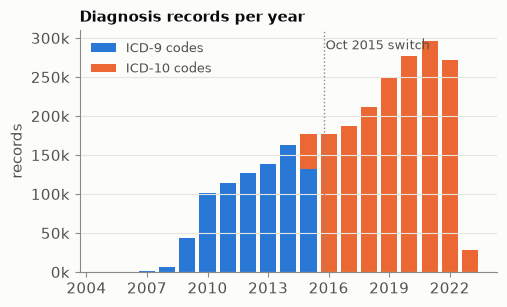

In [5]:
import matplotlib.pyplot as plt

from ehrgraph.data.omop import icd_vocabulary
from ehrgraph.viz import network_figures as nf

nf.apply_style()
d = diagnoses.dropna(subset=["source_value", "time"])
system = [icd_vocabulary(s, when) for s, when in zip(d.source_value, d.time, strict=True)]
counts = (
    d.assign(year=d.time.dt.year, system=system)
    .query("system in ['ICD9CM', 'ICD10CM'] and 2005 <= year <= 2023")
    .groupby(["year", "system"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)
fig = nf.era_by_year_figure(counts)
nf.save(fig, p.figures / "01_billing_codes_by_year.png")
plt.show()

## What we learned

- The tables cover **6,731 patients**, about **944k visits** and **2.57M diagnosis records** (8,758 different diagnoses).
- **Long stay:** 6,998 prediction times from 3,844 patients, and 25.4% of stays are long.
- **New high blood pressure:** 3,511 prediction times from 2,217 patients, and 12.8% get diagnosed within a year.
- We rebuilt these labels ourselves from the tables. In an earlier check against Stanford's official labels they matched on 99.8% (long stay) and 99.4% (blood pressure) of the stays both had. The blood-pressure set is a bit smaller because we properly skip people who were *already* diagnosed. Stanford's own list keeps a few of them by mistake.
- **The cheating version sees about twice as much** (97 vs 48 different diagnoses per stay). That's the future record we're not allowed to use.
- **The code switch is very visible:** ICD-9 until late 2015, ICD-10 after. Same disease, different code, which is why we use the standard concepts from here on.